<a href="https://colab.research.google.com/github/Gaborobles/Programacion-para-IA/blob/main/AF3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

-Carlos Adrian Rivera Salinas 2208957
-Haldir Alejandro Castillo Bautista 2173180
-José Gael alejo López 219294
-Gabriel Villagómez Robles 2208997.

**1. Carga del Conjunto de Datos Público**

Importamos las librerias y usamos pandas para cargar los datos del dataset con pd.read_csv().

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("Primeras filas del dataset original:")
print(df.head())

Primeras filas del dataset original:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


**2. Análisis Exploratorio y Visualización**

Se utiliza df.describe para tener un analisisi estadistico de las variables, df.info y df.isnull para comprobar que no haya valores nulos.
Al final se usa matplotlib para generar un diagrama de dispersión que relaciona la glucosa con el IBM, pandas nos ayuda a separar las personas con diabetes con las que no tienen.

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0


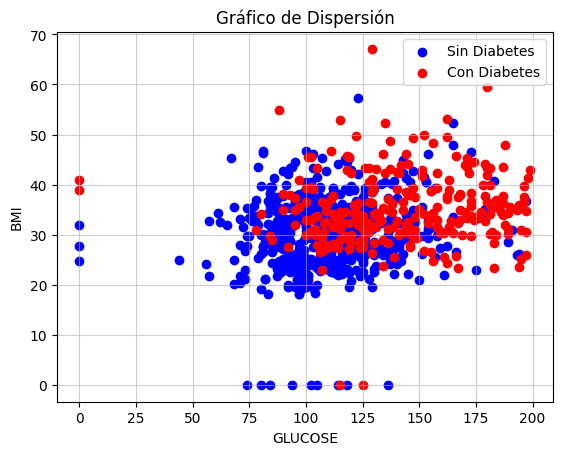

In [ ]:
no_diabetes = df[df['Outcome'] == 0]
diabetes = df[df['Outcome'] == 1]
plt.scatter(no_diabetes['Glucose'], no_diabetes['BMI'], color='blue', label="Sin Diabetes")
plt.scatter(diabetes['Glucose'], diabetes['BMI'], color='red', label="Con Diabetes")
plt.title("Gráfico de Dispersión")
plt.xlabel("GLUCOSE")
plt.ylabel("BMI")
plt.legend()
plt.grid(True, alpha=0.6)
plt.show()

 **3. Limpieza y Preprocesamiento de Datos**

 Limpieza y procesamiento de datos. Con la ayuda de pandas cambiamos los datos con valor 0 de cada columna a valores nulos usando .replace(0, np.nan) para despues a esos valores nulos asignarles los valoresde las medianas de sus respectivas columnas. En este caso se separaron las personas con diabetes y las que no tienen diabetes para asignarles sus medianas por separado y lograr una mejor exactitud. Para terminar se usó Numpy para filtrar la columna de Insulina y que esta solo conserve los valores dentro del rango Intercuartilico.

In [ ]:
ceros=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
df[ceros] = df[ceros].replace(0, np.nan)
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
medianas=df.groupby('Outcome')[ceros].median()
print(medianas)
df[ceros]=df.groupby('Outcome')[ceros].transform(lambda x: x.fillna(x.median()))

         Glucose  BloodPressure  SkinThickness  Insulin    BMI
Outcome                                                       
0          106.0           70.0           27.0    102.5  30.10
1          136.0           74.5           32.0    169.5  34.25


In [ ]:
q1=df['Insulin'].quantile(0.25)
q3=df['Insulin'].quantile(0.75)
IQR=q3-q1
inflim=q1-IQR*1.5
suplim=q3+IQR*1.5

df=df[(df['Insulin']>=inflim) & (df['Insulin']<=suplim)]
print(len(df))

717


**4. Entrenamiento y Evaluación del Árbol de Decisión.**

Se usó Pandas, Scikit-learn y matplotlib para entrenar, testear y generar un arbol de decisión. Primero se asignaron a X las columnas de características independientes y a Y la columna de 'Outcome' que es la que guarda el valor de si tienen o no diabetes. Se dividen los datos del dataset y se asigna solo el 25% de los datos en el dataset (test_size=0.25) para el entrenamiento. Se entrena el arbol de decisión y se evalua el desempeño del modelo usando: accuracy = accuracy_score(y_test, y_pred).
Al final se usa matplotlib para visualizar el arból de decisión.

In [ ]:
X=df.drop('Outcome',axis=1)
Y=df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=42, stratify=Y)
print(X_train.shape, X_test.shape)

(537, 8) (180, 8)


In [ ]:
model = DecisionTreeClassifier(random_state=42, max_depth=3)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print(classification_report(y_test, y_pred))


Accuracy: 0.8944444444444445
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       120
           1       0.83      0.87      0.85        60

    accuracy                           0.89       180
   macro avg       0.88      0.89      0.88       180
weighted avg       0.90      0.89      0.90       180



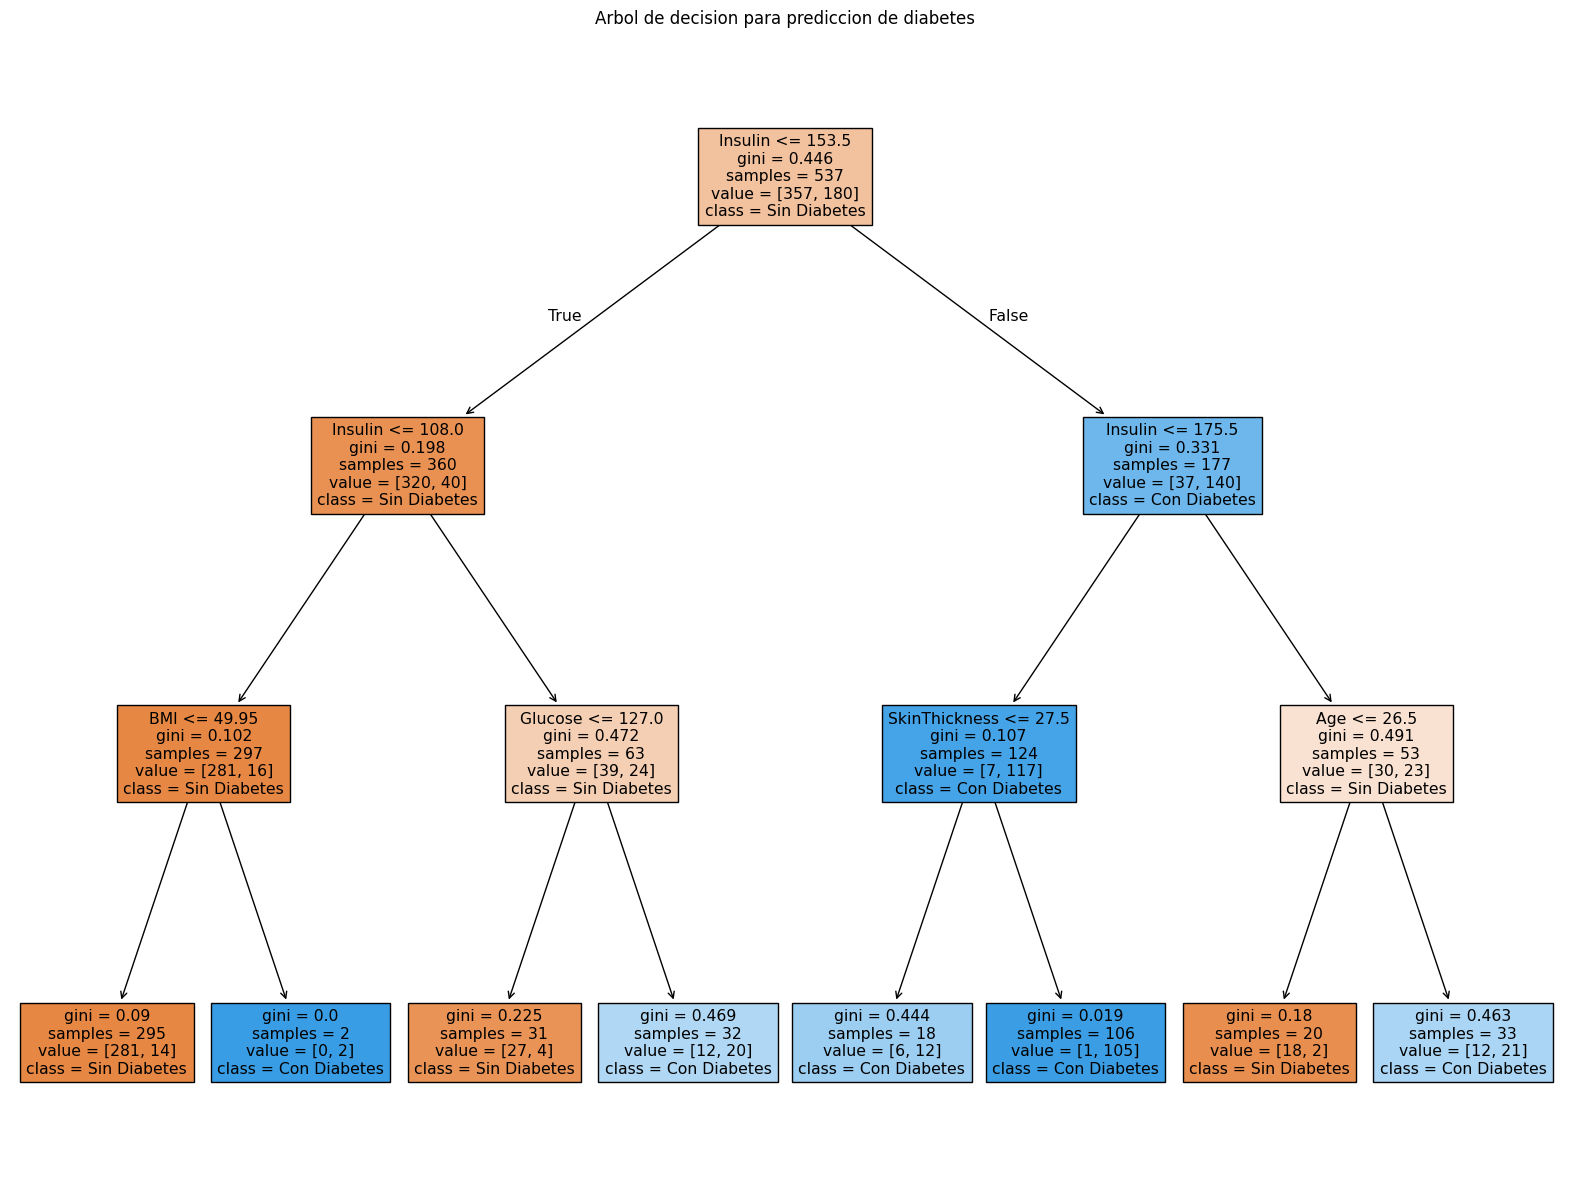

In [ ]:
plt.figure(figsize=(20, 15))
plot_tree(model, filled=True, feature_names=X.columns, class_names=['Sin Diabetes', 'Con Diabetes'])
plt.title("Arbol de decision para prediccion de diabetes")
plt.savefig("decision_tree.png", dpi=300)
plt.show()